# Lab 1-02：模型其實只做一件事——猜下一個 token

**目標**：打開一個真的小模型，親眼看它輸出的機率分布，然後自己寫生成迴圈。

**你會學到**
- embedding 就是查表
- 語言模型是一個「詞表大小」的分類器
- 生成一段話＝把「猜下一個」放進 for 迴圈
- 溫度與 top-p 只是在改抽樣方式
- 幻覺從哪裡來

**前置**：會下載 `Qwen/Qwen2.5-0.5B`（約 1GB）。有 GPU 最好，CPU 也跑得動，只是慢一點。

**對應投影片**：「embedding 就是查表」「語言模型是詞表分類器」「逐字生成是個迴圈」「溫度只管隨機性」「幻覺從哪來」

```
┌──► 已有的 token 序列
│        │
│        ▼
│      LLM（前向傳播一次）
│        │
│        ▼
│      詞表大小的機率分布（softmax）
│        │
│        ▼
│      抽樣：溫度、top-p 只改這一步
│        │
│        ▼
│      下一個 token
│        │
└────────┘ 接到後面，再猜一次
```

*圖：生成一段話就是這個迴圈。模型本身只負責中間那格「算機率」；溫度和 top-p 只動「抽樣」那一格。*

## Step 1：載入模型

這裡用的是**基礎模型**（base model），只做過預訓練、沒教過對話，最適合看「猜下一個字」的原始行為。

In [1]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32).to(device).eval()

print(f"參數量：{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M，詞表大小：{len(tok)}，裝置：{device}")

參數量：494M，詞表大小：151665，裝置：cuda


## Step 2：文字 → token id

In [2]:
prompt = "魯夫想成為"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
print(ids)
print([tok.decode(i) for i in ids[0]])

tensor([[115571,  99818,  99172, 106027]], device='cuda:0')
['魯', '夫', '想', '成為']


## Step 3：embedding 就是查表

模型第一層是一張大表：每個 token id 對應一列向量。查表＝取出第 id 列，沒有任何計算。

In [3]:
table = model.get_input_embeddings().weight
print("embedding 表的形狀：", tuple(table.shape), "（詞表大小 × 向量維度）")

by_hand = table[ids[0]]                       # 自己按 id 取列
by_model = model.get_input_embeddings()(ids)[0]  # 模型的 embedding 層
print("兩者一樣嗎？", torch.equal(by_hand, by_model))

embedding 表的形狀： (151936, 896) （詞表大小 × 向量維度）
兩者一樣嗎？ True


## Step 4：模型輸出的是「每個 token 的分數」

跑一次前向傳播，最後一個位置會得到一個長度＝詞表大小的向量（logits）。
套上 softmax，就是「下一個 token 是誰」的機率分布。這跟影像分類的最後一層是同一件事，只是類別有十幾萬個。

In [4]:
with torch.no_grad():
    logits = model(ids).logits

print("logits 形狀：", tuple(logits.shape), "（批次 × 序列長度 × 詞表大小）")

probs = torch.softmax(logits[0, -1], dim=-1)
top = torch.topk(probs, 10)
for p, i in zip(top.values, top.indices):
    print(f"{p.item():6.1%}  {tok.decode(i)!r}")

logits 形狀： (1, 4, 151936) （批次 × 序列長度 × 詞表大小）
 16.6%  '一個'
  9.3%  '一名'
  4.5%  '一位'
  1.5%  '哪'
  1.5%  '什麼'
  1.4%  '世界'
  1.4%  '醫生'
  1.2%  '足球'
  1.0%  '一家'
  0.9%  '一'


## Step 5：自己寫生成迴圈

生成一整段話，就是：猜一個 → 接到後面 → 再猜一個。這裡每次都挑機率最高的（greedy）。

In [5]:
def generate_greedy(prompt: str, steps: int = 20) -> str:
    ids = tok(prompt, return_tensors="pt").input_ids.to(device)
    for _ in range(steps):
        with torch.no_grad():
            next_id = model(ids).logits[0, -1].argmax()
        ids = torch.cat([ids, next_id.view(1, 1)], dim=1)
    return tok.decode(ids[0])


print(generate_greedy("魯夫想成為"))

魯夫想成為一個成功的商人，他需要在哪些方面進行投資？
作為一個成功的商人，魯夫需要


沒有任何「理解句子再回答」的步驟，只有一個迴圈。投影片上的「Agent＝模型＋迴圈」，最底層也是這個迴圈。

## Step 6：溫度只是在壓扁或拉尖分布

抽樣前把 logits 除以溫度 T：T 小，高分的更突出（穩定）；T 大，分布被壓平（隨機）。

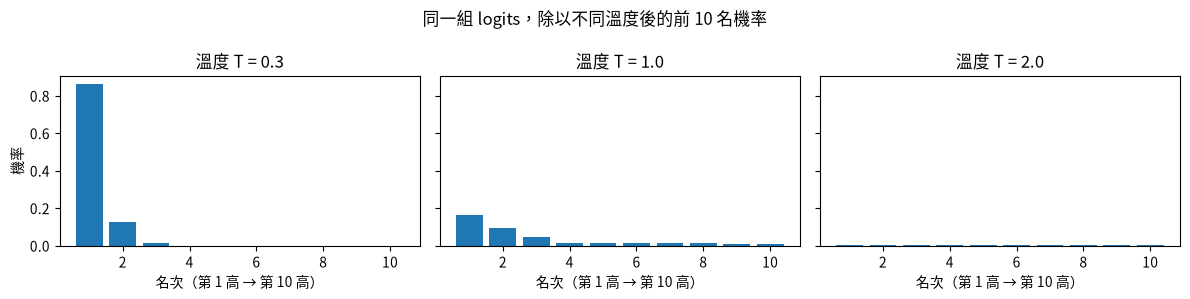

In [6]:
import matplotlib.pyplot as plt
from course_utils.viz import setup_cjk

setup_cjk()
last = logits[0, -1]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, T in zip(axes, [0.3, 1.0, 2.0]):
    p = torch.softmax(last / T, dim=-1)
    ax.bar(range(1, 11), torch.topk(p, 10).values.cpu())
    ax.set_title(f"溫度 T = {T}")
    ax.set_xlabel("名次（第 1 高 → 第 10 高）")
axes[0].set_ylabel("機率")
fig.suptitle("同一組 logits，除以不同溫度後的前 10 名機率")
plt.tight_layout()
plt.show()

In [7]:
def sample(prompt: str, steps: int = 20, temperature: float = 1.0, top_p: float = 1.0) -> str:
    ids = tok(prompt, return_tensors="pt").input_ids.to(device)
    for _ in range(steps):
        with torch.no_grad():
            logits = model(ids).logits[0, -1] / temperature
        probs = torch.softmax(logits, dim=-1)
        # top-p：只留累積機率到 top_p 為止的那些 token
        sorted_p, sorted_i = torch.sort(probs, descending=True)
        keep = torch.cumsum(sorted_p, dim=0) - sorted_p < top_p
        sorted_p = sorted_p * keep
        choice = sorted_i[torch.multinomial(sorted_p / sorted_p.sum(), 1)]
        ids = torch.cat([ids, choice.view(1, 1)], dim=1)
    return tok.decode(ids[0])


torch.manual_seed(0)
for T in [0.3, 1.5]:
    print(f"--- T = {T}")
    for _ in range(3):
        print(sample("魯夫想成為", temperature=T, top_p=0.9))

--- T = 0.3
魯夫想成為一個出色的足球員，他需要通過一系列的練習和訓練來提高自己的技能。他
魯夫想成為一個出色的演員，他需要通過多少個演員角色才能成為一個成功的演員？

魯夫想成為一名出色的鋼琴演奏家，他需要在以下哪些方面提高自己的技能？
A. �
--- T = 1.5
魯夫想成為部 следброс Fürchten Driving Steaturiest所质疑隨著科研DNA Experts四位後期组建 Luke
魯夫想成為_OOP_Array\Object Hồ châu thuê nhất___ PhD
.In其他人 descricao software괴 santicularly为什么未必
魯夫想成為芭芭 которой教父亲（Only Bishop） 是う醿判（Wreckon），時候


T = 1.5 時冷門 token 也常被抽中，句子很快變成多國語言夾雜的亂碼。
溫度不會讓模型變聰明或變笨，它只決定「要不要常挑第二、第三名」。
要精準輸出（JSON、SQL、程式碼）時用低溫；要發想時才調高。

## Step 7：幻覺從哪來

模型每一步都**一定**會輸出一個機率分布，結構上沒有「我不知道」這個選項。
問它一件語料裡不存在的事，它照樣會接出一段很順的話。

In [8]:
print(generate_greedy("台灣第一位登上月球的太空人是", steps=30))

台灣第一位登上月球的太空人是？
A. 郭守敬
B. 王亚平
C. 翟志刚
D. 刘洋


從來沒有台灣人登上月球，但模型給了一份很像考題的選項，裡面還是真實存在的人名。
它沒有查證，只是在模仿預訓練語料裡「考題」的樣子：內容是「最像下一句」的東西，不保證是真的。
後面的 RAG（模組 3）就是在解決這件事：先把相關資料找出來塞進 prompt，讓它照著資料回答。

## 試試看

1. 把 Step 4 的 prompt 換成英文 `"Luffy wants to become"`，比較前 10 名。
2. 把 `MODEL` 換成對話版 `Qwen/Qwen2.5-0.5B-Instruct`，Step 7 的回答有變嗎？為什麼還是可能亂講？
3. 在 `sample` 裡把 `top_p` 設成 0.5，觀察句子是不是變得更保守。

## 小結

- embedding 是查表，模型最後一層是「詞表大小」的分類器。
- 生成＝猜下一個 token 的迴圈；溫度和 top-p 只改抽樣方式。
- 模型永遠會給答案，所以會幻覺。下一本：中間那一大段 Transformer 在算什麼。